# 07 · ¿Sobrevive la señal al controlar confusores biológicos y de calidad?

El notebook 05 mostró que la expresión predice la parte del CPS que **no** explican el número de células y los
recuentos. El EDA (06) añadió dos sospechosos más:

- **APOE4**, el único confusor asociado al ADNC tras la corrección múltiple (y el sexo y la edad, por precaución).
- **El % mitocondrial**, algo mayor en High en los 6 tipos celulares (calidad del ARN o daño celular).

Repetimos las dos pruebas del notebook 05 con tres conjuntos de variables de control, de menos a más:

| Conjunto | Variables (por donante) |
|---|---|
| A. Técnicas | log n_celulas y log recuentos de los 6 tipos (12) — lo del notebook 05 |
| B. + biológicas | A + APOE4, sexo, edad y marca de "80 o más" (16) |
| C. + calidad | B + mediana del % mitocondrial de cada tipo (22) |

Si la señal se mantiene con C, no se explica por esas variables. Las permutaciones (20) se hacen solo con C, el
conjunto más exigente.

**Ejecución** (~10–15 min): `jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=7200 notebooks\07_confusores.ipynb`

In [1]:
import json
import sys
import warnings
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))
from tfm import baselines as B
from tfm import data
from tfm import evaluation as E
from tfm.config import load_config

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")

cfg = load_config(ROOT)
COL, PB, EV, BL = cfg["columns"], cfg["pseudobulk"], cfg["evaluation"], cfg["baselines"]
SEED = cfg["seed"]
TABLAS, FIGS = cfg["paths"]["tables"], cfg["paths"]["figures"]
CPS = "Continuous Pseudo-progression Score"

def guardar(df, nombre):
    df.to_csv(TABLAS / f"{nombre}.csv", encoding="utf-8"); return df

def guardar_fig(fig, nombre):
    fig.savefig(FIGS / f"{nombre}.png", dpi=150, bbox_inches="tight")

pb = ad.read_h5ad(ROOT / PB["file"])
pb_ig = ad.read_h5ad(ROOT / PB["file_igualado"])
datos, y = B.build_type_data(pb_ig, pb, cfg)
cps = pb.obs.groupby(pb.obs[COL["donor"]].astype(str), observed=True)[CPS].first().astype(float).reindex(y.index)
ok = cps.notna()
datos = {t: (c.loc[c.index.isin(cps.index[ok])], tec.loc[tec.index.isin(cps.index[ok])]) for t, (c, tec) in datos.items()}
cps, y = cps[ok], y[ok]

tec, _ = E.technical_features(pb, cfg)
tec = tec.reindex(cps.index).fillna(0)
obs, _, _, _, _ = data.read_obs_var(cfg["paths"]["subset"])
cov = E.donor_covariates(obs, cfg).reindex(cps.index)
bio = cov[["apoe4", "sexo_mujer", "edad", "edad_80_o_mas"]]
mt = cov[[c for c in cov.columns if c.startswith("mt_")]]
CONTROLES = {"A. técnicas": tec, "B. + biológicas": tec.join(bio), "C. + calidad": tec.join(bio).join(mt)}
for k, v in CONTROLES.items():
    print(f"{k:18s} {v.shape[1]} variables, {int(v.isna().sum().sum())} valores perdidos")
print("\nCorrelación de Spearman de cada covariable con el CPS:")
display(cov.apply(lambda c: pd.Series(stats.spearmanr(c, cps), index=["rho", "p"])).T.round(3))

def ridge_expr(n_tech):
    return make_pipeline(B.LogCPMTopVar(BL["n_genes"], PB["min_cpm"], PB["min_frac"], n_tech), StandardScaler(),
                         RidgeCV(alphas=np.logspace(0, 5, 11)))

def ridge_tec():
    return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 11)))

splits = E.donor_splits(y.values, n_splits=EV["n_splits"], n_repeats=EV["n_repeats_baselines"], seed=SEED)

A. técnicas        12 variables, 0 valores perdidos
B. + biológicas    16 variables, 0 valores perdidos
C. + calidad       22 variables, 0 valores perdidos

Correlación de Spearman de cada covariable con el CPS:


,rho,p
apoe4,0.450,0.000
sexo_mujer,0.091,0.439
edad,-0.177,0.131
edad_80_o_mas,-0.096,0.415
mt_OLG,0.452,0.000
mt_MGC,0.535,0.000
mt_AST,0.439,0.000
mt_VIP-GABA,0.514,0.000
mt_SST-GABA,0.446,0.000
mt_L2IT-GLU,0.496,0.000


## 1. Correlación parcial con cada conjunto de control

Misma regresión del CPS que en el notebook 05 (mismas particiones). Para cada tipo y para la fusión: correlación de
Spearman entre la predicción media y el CPS real descontando cada conjunto de variables. Contraste de una cola
(solo una correlación positiva cuenta como evidencia; la validación cruzada sin señal sesga hacia valores
negativos, así que es conservador).

In [2]:
_, pred = B.run_regression(datos, cps, splits, {"ridge (expresión)": (ridge_expr, "expresion")})
_, Yf = B.fuse_regression(pred, cps, "ridge (expresión)")
filas = []
for t, Y in list({t: pred[("ridge (expresión)", t)] for t in datos}.items()) + [("fusión", Yf)]:
    media = np.nanmean(Y, axis=0)
    m = ~np.isnan(media)
    fila = {"tipo": t, "n": int(m.sum()), "spearman": pd.Series(media[m]).corr(pd.Series(cps.values[m]), method="spearman")}
    for k, Z in CONTROLES.items():
        r, p = E.partial_spearman(media[m], cps.values[m], Z.values[m])
        fila[f"parcial {k}"] = r
        fila[f"p {k}"] = p / 2 if r > 0 else 1 - p / 2
    filas.append(fila)
parcial = guardar(pd.DataFrame(filas).set_index("tipo"), "confusores_correlacion_parcial")
display(parcial.round(3))

  AST        ridge (expresión)                 6 s


  L2IT-GLU   ridge (expresión)                13 s


  MGC        ridge (expresión)                20 s


  OLG        ridge (expresión)                27 s


  SST-GABA   ridge (expresión)                33 s


  VIP-GABA   ridge (expresión)                39 s


,n,spearman,parcial A. técnicas,p A. técnicas,parcial B. + biológicas,p B. + biológicas,parcial C. + calidad,p C. + calidad
tipo,,,,,,,,
AST,64,0.565,0.441,0.001,0.462,0.000,0.364,0.009
L2IT-GLU,63,0.473,0.317,0.012,0.421,0.002,0.374,0.008
MGC,63,0.524,0.333,0.008,0.432,0.001,0.316,0.022
OLG,60,0.510,0.473,0.000,0.472,0.001,0.425,0.004
SST-GABA,63,0.467,0.312,0.013,0.379,0.004,0.265,0.047
VIP-GABA,66,0.484,0.228,0.049,0.294,0.019,0.186,0.114
fusión,74,0.582,0.366,0.002,0.455,0.000,0.445,0.000


## 2. Modelo de residuos con cada conjunto de control

En cada pliegue: ridge sobre el conjunto de control predice el CPS; la expresión de cada tipo predice el residuo;
en test se compara con el residuo real.

In [3]:
cols = ["spearman_tecnico", "spearman_tecnico_mas_expresion", "spearman_residuo"]
tablas = {}
for k, Z in CONTROLES.items():
    print(k)
    met_res, pred_res, real, pred_tec = B.run_residual_regression(datos, cps, Z, splits, ridge_expr, ridge_tec)
    fus_res, _ = B.fuse_residual(pred_res, cps, real, pred_tec)
    tablas[k] = B.summarize_by(pd.concat([met_res, fus_res]), keys=("tipo",), metricas=cols)
tabla_res = pd.concat(tablas, names=["control"])
tabla_res.columns = [c.replace("spearman_tecnico", "spearman_control") for c in tabla_res.columns]
guardar(tabla_res, "confusores_residuos")
resumen_res = tabla_res["spearman_residuo_media"].unstack("control")[list(CONTROLES)]
print("Spearman entre residuo predicho por la expresión y residuo real:")
display(resumen_res.round(3))
print("Control solo frente a control + expresión (Spearman con el CPS):")
display(tabla_res[["spearman_control_media", "spearman_control_mas_expresion_media"]].unstack("control").round(3))

A. técnicas


  AST             6 s


  L2IT-GLU       11 s


  MGC            17 s


  OLG            22 s


  SST-GABA       28 s


... (12 outputs left out)

  VIP-GABA       34 s
Spearman entre residuo predicho por la expresión y residuo real:


control,A. técnicas,B. + biológicas,C. + calidad
tipo,,,
AST,0.295,0.284,0.248
L2IT-GLU,0.370,0.348,0.353
MGC,0.392,0.396,0.359
OLG,0.458,0.411,0.399
SST-GABA,0.450,0.413,0.410
VIP-GABA,0.379,0.354,0.334
fusión,0.356,0.320,0.293


Control solo frente a control + expresión (Spearman con el CPS):


spearman_control_media                              spearman_control_mas_expresion_media                             
control             A. técnicas B. + biológicas C. + calidad                          A. técnicas B. + biológicas C. + calidad
tipo                                                                                                                          
AST                       0.477           0.531        0.570                                0.593           0.629        0.636
L2IT-GLU                  0.375           0.444        0.489                                0.493           0.531        0.539
MGC                       0.426           0.488        0.534                                0.569           0.602        0.613
OLG                       0.438           0.517        0.553                                0.593           0.619        0.632
SST-GABA                  0.379           0.463        0.508                                0.547           0.589        0.602
VIP-GABA                  0.415           0.497        0.542                                0.554           0.590        0.611
fusión                    0.505           0.570        0.610                                0.621           0.662        0.672

### Permutación (conjunto C)

Barajamos el CPS entre donantes y repetimos todo el proceso (control C + expresión sobre el residuo) 20 veces.

In [4]:
N_PERM = 20
rng = np.random.default_rng(SEED)
nulo = {t: [] for t in list(datos) + ["fusión"]}
for i in range(N_PERM):
    cp = pd.Series(rng.permutation(cps.values), index=cps.index)
    sp_ = E.donor_splits(y.values, n_splits=EV["n_splits"], n_repeats=1, seed=SEED + i)
    m_, pr_, re_, pt_ = B.run_residual_regression(datos, cp, CONTROLES["C. + calidad"], sp_, ridge_expr, ridge_tec, verbose=False)
    f_, _ = B.fuse_residual(pr_, cp, re_, pt_)
    for _, fila in pd.concat([m_, f_]).iterrows():
        nulo[fila["tipo"]].append(fila["spearman_residuo"])
    print(f"\r  permutación {i + 1}/{N_PERM}", end="")
print()

obs_c = resumen_res["C. + calidad"]
perm = pd.DataFrame({t: {"observado": obs_c[t], "nulo_media": np.mean(v), "nulo_p95": np.percentile(v, 95),
                         "p_empirico": (1 + np.sum(np.array(v) >= obs_c[t])) / (1 + len(v))}
                     for t, v in nulo.items()}).T
guardar(perm, "confusores_residuos_permutacion")
display(perm.round(3))

  permutación 1/20

  permutación 2/20

  permutación 3/20

  permutación 4/20

  permutación 5/20

  permutación 6/20

... (11 outputs left out)

  permutación 18/20

  permutación 19/20

  permutación 20/20


,observado,nulo_media,nulo_p95,p_empirico
AST,0.248,-0.110,0.044,0.048
L2IT-GLU,0.353,-0.064,0.222,0.048
MGC,0.359,-0.062,0.137,0.048
OLG,0.399,-0.093,0.106,0.048
SST-GABA,0.410,-0.041,0.252,0.048
VIP-GABA,0.334,-0.015,0.211,0.048
fusión,0.293,-0.054,0.173,0.048


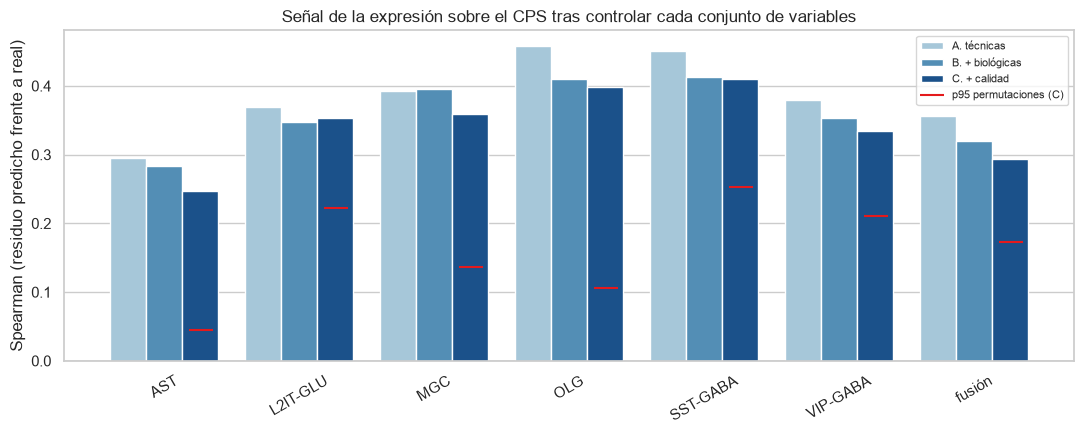

In [5]:
orden = sorted(datos) + ["fusión"]
d = resumen_res.reset_index().melt(id_vars="tipo", var_name="control", value_name="spearman_residuo")
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(data=d, x="tipo", y="spearman_residuo", hue="control", order=orden, ax=ax,
            palette=["#9ecae1", "#4292c6", "#08519c"])
ax.scatter(np.arange(len(orden)) + 0.27, [perm.loc[t, "nulo_p95"] for t in orden], marker="_", s=300, color="#e41a1c",
           zorder=3, label="p95 permutaciones (C)")
ax.axhline(0, color="k", lw=0.8); ax.set_xlabel("")
ax.set_ylabel("Spearman (residuo predicho frente a real)")
ax.set_title("Señal de la expresión sobre el CPS tras controlar cada conjunto de variables")
ax.legend(fontsize=8, bbox_to_anchor=(1, 1)); ax.tick_params(axis="x", rotation=30)
fig.tight_layout(); guardar_fig(fig, "confusores_residuos"); plt.show()

In [6]:
resumen = {
    "correlacion_parcial": parcial.round(4).to_dict(orient="index"),
    "residuo_por_control": resumen_res.round(3).to_dict(),
    "permutacion_C": perm.round(3).to_dict(orient="index"),
}
(TABLAS / "confusores_resumen.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(resumen, indent=2, ensure_ascii=False))

{
  "correlacion_parcial": {
    "AST": {
      "n": 64,
      "spearman": 0.5651,
      "parcial A. técnicas": 0.4414,
      "p A. técnicas": 0.0005,
      "parcial B. + biológicas": 0.4616,
      "p B. + biológicas": 0.0005,
      "parcial C. + calidad": 0.3643,
      "p C. + calidad": 0.0088
    },
    "L2IT-GLU": {
      "n": 63,
      "spearman": 0.4731,
      "parcial A. técnicas": 0.3168,
      "p A. técnicas": 0.0118,
      "parcial B. + biológicas": 0.4207,
      "p B. + biológicas": 0.0016,
      "parcial C. + calidad": 0.3738,
      "p C. + calidad": 0.008
    },
    "MGC": {
      "n": 63,
      "spearman": 0.5242,
      "parcial A. técnicas": 0.333,
      "p A. técnicas": 0.0085,
      "parcial B. + biológicas": 0.4317,
      "p B. + biológicas": 0.0012,
      "parcial C. + calidad": 0.3157,
      "p C. + calidad": 0.0222
    },
    "OLG": {
      "n": 60,
      "spearman": 0.5103,
      "parcial A. técnicas": 0.4731,
      "p A. técnicas": 0.0003,
      "parcial B. + biol